<a href="https://colab.research.google.com/github/eaaguirreb/Estructuras-de-datos/blob/Next/Arboles_Estructuras_de_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌳 Árboles en Estructuras de Datos
**Curso:** Estructura de Datos · Ciencias de Datos e Inteligencia Artificial

Este notebook explica la teoría de los árboles y **dibuja cada árbol** para que veas la estructura mientras aprendes.

| Parte | Tema |
|---|---|
| 0 | Configuración del entorno |
| 1 | Qué es un árbol y su vocabulario |
| 2 | Medir un árbol: peso, altura, grado |
| 3 | Árbol general (n-ario): sistema de archivos |
| 4 | Árbol binario de búsqueda (BST) |
| 5 | Recorridos: pre-orden, in-orden, post-orden y por niveles |
| 6 | Experimento: BST aleatorio vs. ordenado (peor caso) |
| 7 | Árbol balanceado |
| 8 | Heap (montículo) y colas de prioridad |
| 9 | Trie (árbol de prefijos) |
| 10 | Árbol de decisión en Machine Learning |
| 11 | Taller para practicar |

**Cómo usarlo:** ejecuta las celdas en orden (`Shift + Enter`) o usa *Entorno de ejecución → Ejecutar todas*.

## 0. Configuración del entorno
Este notebook **no necesita GPU**: los árboles se dibujan con `matplotlib` y el último ejemplo usa `scikit-learn`, ambos incluidos en Colab. La celda siguiente verifica las librerías e instala solo las que falten.

In [ ]:
# Verifica las librerías necesarias e instala solo las que falten.
import importlib
import subprocess
import sys

LIBRERIAS = {"matplotlib": "matplotlib", "numpy": "numpy", "sklearn": "scikit-learn"}

for modulo, paquete in LIBRERIAS.items():
    try:
        importlib.import_module(modulo)
        print(f"✔ {paquete} disponible")
    except ImportError:
        print(f"✘ {paquete} no encontrado; instalando...")
        subprocess.run([sys.executable, "-m", "pip", "install", paquete, "--quiet"],
                       check=False)

✔ matplotlib disponible
✔ numpy disponible
✔ scikit-learn disponible


In [ ]:
# Verifica si hay GPU (solo informativo: este notebook funciona en CPU).
try:
    import torch
    if torch.cuda.is_available():
        print(f"GPU disponible: {torch.cuda.get_device_name(0)}")
    else:
        print("Sin GPU: no hay problema, este notebook corre en CPU.")
except ImportError:
    print("PyTorch no está instalado; no se necesita para este notebook.")

Sin GPU: no hay problema, este notebook corre en CPU.


In [ ]:
# Importaciones generales y estilo de las gráficas.
import random
import time
import heapq
from collections import deque
from statistics import mean

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
})

# Paleta usada en todos los dibujos.
COLOR_NODO = "#FDFDF9"
COLOR_BORDE = "#14213D"
COLOR_RAIZ = "#F2A541"
COLOR_RESALTE = "#E76F51"
COLOR_HOJA = "#BFE6DD"
COLORES_NIVEL = ["#F2A541", "#8ECAE6", "#BFE6DD", "#E9C46A", "#CDB4DB", "#D8E2DC"]

random.seed(42)
print("Entorno listo ✔")

Entorno listo ✔


## 🖌️ Herramienta para dibujar árboles
Esta función es el corazón visual del notebook. Recibe la **raíz** de cualquier árbol y dos funciones:

- `hijos_fn(nodo)`: devuelve la lista de hijos del nodo.
- `etiqueta_fn(nodo)`: devuelve el texto que se muestra dentro del círculo.

**Algoritmo de dibujo:** las hojas se colocan de izquierda a derecha y cada padre queda centrado sobre sus hijos. La coordenada vertical es la profundidad (la raíz arriba). Para árboles binarios, un hijo vacío (`None`) reserva su lugar, así se distingue un hijo izquierdo de uno derecho.

In [ ]:
# Calcula posiciones y dibuja cualquier árbol con matplotlib.


def calcular_posiciones(raiz, hijos_fn):
    """Devuelve {id(nodo): (x, y)} y la lista de nodos en orden de visita.

    Las hojas reciben x consecutivas; cada padre se centra sobre sus hijos.
    Un hijo None reserva medio espacio (útil en árboles binarios).
    """
    posiciones = {}
    nodos = []
    siguiente_x = [0.0]

    def visitar(nodo, profundidad):
        nodos.append(nodo)
        hijos = hijos_fn(nodo)
        if not hijos or all(h is None for h in hijos):
            x = siguiente_x[0]
            siguiente_x[0] += 1
        else:
            xs = []
            for hijo in hijos:
                if hijo is None:
                    xs.append(siguiente_x[0])
                    siguiente_x[0] += 0.6
                else:
                    xs.append(visitar(hijo, profundidad + 1))
            x = mean(xs)
        posiciones[id(nodo)] = (x, -profundidad)
        return x

    visitar(raiz, 0)
    return posiciones, nodos


def dibujar_arbol(raiz, hijos_fn, etiqueta_fn, titulo="", resaltar=None,
                  orden_visita=None, colorear_niveles=False, marcar_hojas=False,
                  ax=None, tam_nodo=1100, tam_fuente=12, espacio_x=1.0):
    """Dibuja un árbol.

    Args:
        raiz: nodo raíz del árbol.
        hijos_fn: función nodo -> lista de hijos (puede contener None).
        etiqueta_fn: función nodo -> texto dentro del círculo.
        titulo: título de la gráfica.
        resaltar: conjunto de nodos a pintar con color de resalte.
        orden_visita: lista de nodos; se escribe su posición (1, 2, 3...).
        colorear_niveles: pinta cada nivel con un color distinto.
        marcar_hojas: pinta las hojas con un color propio.
        ax: eje de matplotlib existente (opcional).
        espacio_x: separación horizontal entre nodos (súbela si las
            etiquetas son largas).
    """
    if raiz is None:
        print("⚠ El árbol está vacío: no hay nada que dibujar.")
        return None
    if not callable(hijos_fn) or not callable(etiqueta_fn):
        raise TypeError("hijos_fn y etiqueta_fn deben ser funciones.")

    posiciones, nodos = calcular_posiciones(raiz, hijos_fn)
    posiciones = {k: (x * espacio_x, y) for k, (x, y) in posiciones.items()}
    resaltar_ids = {id(n) for n in (resaltar or [])}
    orden_ids = {id(n): i + 1 for i, n in enumerate(orden_visita or [])}

    ancho = max(4, (max(p[0] for p in posiciones.values()) + 1) * 0.9)
    alto = max(2.5, (-min(p[1] for p in posiciones.values()) + 1) * 1.1)
    if ax is None:
        _, ax = plt.subplots(figsize=(min(ancho, 16), min(alto, 10)))

    # 1) Aristas primero, para que queden debajo de los círculos.
    for nodo in nodos:
        x1, y1 = posiciones[id(nodo)]
        for hijo in hijos_fn(nodo) or []:
            if hijo is None:
                continue
            x2, y2 = posiciones[id(hijo)]
            en_camino = id(nodo) in resaltar_ids and id(hijo) in resaltar_ids
            ax.plot([x1, x2], [y1, y2],
                    color=COLOR_RESALTE if en_camino else COLOR_BORDE,
                    linewidth=3.5 if en_camino else 1.6, zorder=1)

    # 2) Nodos y etiquetas.
    for nodo in nodos:
        x, y = posiciones[id(nodo)]
        hijos_reales = [h for h in (hijos_fn(nodo) or []) if h is not None]
        if id(nodo) in resaltar_ids:
            color = COLOR_RESALTE
        elif colorear_niveles:
            color = COLORES_NIVEL[int(-y) % len(COLORES_NIVEL)]
        elif nodo is raiz:
            color = COLOR_RAIZ
        elif marcar_hojas and not hijos_reales:
            color = COLOR_HOJA
        else:
            color = COLOR_NODO
        ax.scatter(x, y, s=tam_nodo, color=color, edgecolors=COLOR_BORDE,
                   linewidths=1.8, zorder=2)
        ax.text(x, y, etiqueta_fn(nodo), ha="center", va="center",
                fontsize=tam_fuente, fontweight="bold", color=COLOR_BORDE, zorder=3)
        if id(nodo) in orden_ids:
            ax.text(x + 0.28, y + 0.28, str(orden_ids[id(nodo)]), ha="center",
                    va="center", fontsize=9, color="white", zorder=4,
                    bbox=dict(boxstyle="circle,pad=0.25", fc=COLOR_BORDE, ec="none"))

    ax.set_title(titulo)
    ax.set_xlim(min(p[0] for p in posiciones.values()) - 0.8,
                max(p[0] for p in posiciones.values()) + 0.8)
    ax.set_ylim(min(p[1] for p in posiciones.values()) - 0.7, 0.7)
    ax.axis("off")
    return ax


print("Función dibujar_arbol lista ✔")

Función dibujar_arbol lista ✔


## 1. ¿Qué es un árbol?
Un **árbol** es una estructura de datos **no lineal y jerárquica** formada por **nodos** unidos por **aristas**.

- Cada nodo tiene **un único padre**, excepto la **raíz**, que no tiene padre.
- Cada nodo puede tener **0 o más hijos**.
- **No hay ciclos:** entre dos nodos existe un solo camino. Un árbol con *n* nodos tiene *n − 1* aristas.
- **Definición recursiva:** un árbol es vacío, o es una raíz con una lista de subárboles. Por eso casi todos sus algoritmos son recursivos.

### Vocabulario
| Término | Significado |
|---|---|
| Raíz | Primer nodo; no tiene padre |
| Padre / Hijo | Relación directa entre dos nodos |
| Hermanos | Nodos con el mismo padre |
| Hoja | Nodo sin hijos |
| Nodo interno (rama) | Nodo con al menos un hijo |
| Subárbol | Un nodo y toda su descendencia |

**Ejemplo real:** el organigrama de una universidad (Rector → Vicerrectores → Decanos).

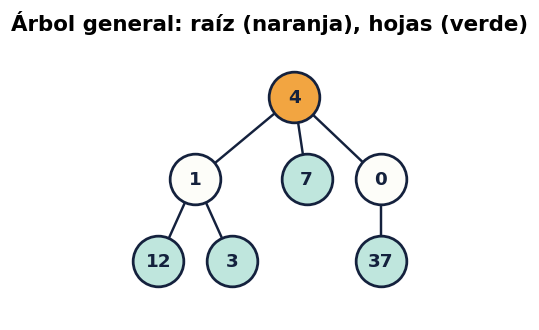

In [ ]:
# Define un nodo de árbol general y construye el árbol de ejemplo.


class Nodo:
    """Nodo de un árbol general: un valor y una lista de hijos."""

    def __init__(self, valor):
        self.valor = valor
        self.hijos = []

    def agregar(self, *hijos):
        """Agrega uno o varios hijos y devuelve el propio nodo (encadenable)."""
        for hijo in hijos:
            if not isinstance(hijo, Nodo):
                raise TypeError(f"Se esperaba un Nodo y llegó {type(hijo).__name__}")
            self.hijos.append(hijo)
        return self

    def __repr__(self):
        return f"Nodo({self.valor!r})"


def hijos_general(nodo):
    """Hijos de un nodo de árbol general."""
    return nodo.hijos


def etiqueta_valor(nodo):
    """Texto del nodo: su valor."""
    return str(nodo.valor)


# Árbol del material de apoyo: 4 -> (1, 7, 0); 1 -> (12, 3); 0 -> (34)
raiz = Nodo(4).agregar(
    Nodo(1).agregar(Nodo(12), Nodo(3)),
    Nodo(7),
    Nodo(0).agregar(Nodo(37)),
)

dibujar_arbol(raiz, hijos_general, etiqueta_valor,
              titulo="Árbol general: raíz (naranja), hojas (verde)",
              marcar_hojas=True)
plt.show()

## 2. Medir un árbol
| Medida | Definición | Fórmula recursiva |
|---|---|---|
| **Peso** (tamaño) | Número total de nodos | `1 + Σ peso(hijo)` |
| **Altura** | Camino más largo (en aristas) de la raíz a una hoja | `0` si es hoja; si no `1 + max(altura(hijo))` |
| **Grado** | Mayor número de hijos de un nodo | `max(len(hijos), grado(hijo)...)` |
| **Profundidad / nivel** | Distancia de un nodo a la raíz | raíz = 0 |

> ⚠️ **Convención:** aquí la raíz está en el **nivel 0** y la altura se cuenta en **aristas**. Algunos textos empiezan en 1.

**¿Por qué importa la altura?** Buscar un dato baja por un solo camino, así que el costo depende de la altura, no del total de nodos.

Peso   : 7
Altura : 2
Grado  : 3
Hojas  : [12, 3, 7, 37]


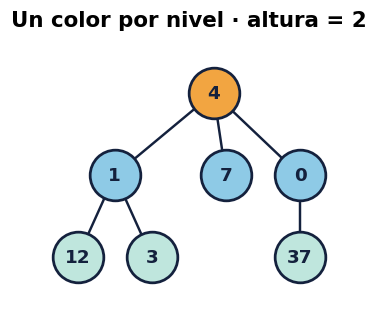

In [ ]:
# Calcula peso, altura, grado y hojas de forma recursiva.


def peso(nodo):
    """Número total de nodos del (sub)árbol."""
    if nodo is None:
        return 0
    return 1 + sum(peso(h) for h in nodo.hijos)


def altura(nodo):
    """Altura en aristas: 0 para una hoja, -1 para un árbol vacío."""
    if nodo is None:
        return -1
    if not nodo.hijos:          # caso base: hoja
        return 0
    return 1 + max(altura(h) for h in nodo.hijos)


def grado(nodo):
    """Mayor número de hijos que tiene algún nodo."""
    if nodo is None:
        return 0
    return max([len(nodo.hijos)] + [grado(h) for h in nodo.hijos])


def hojas(nodo):
    """Lista de valores de las hojas."""
    if nodo is None:
        return []
    if not nodo.hijos:
        return [nodo.valor]
    return [v for h in nodo.hijos for v in hojas(h)]


print(f"Peso   : {peso(raiz)}")
print(f"Altura : {altura(raiz)}")
print(f"Grado  : {grado(raiz)}")
print(f"Hojas  : {hojas(raiz)}")

dibujar_arbol(raiz, hijos_general, etiqueta_valor,
              titulo=f"Un color por nivel · altura = {altura(raiz)}",
              colorear_niveles=True)
plt.show()

## 3. Árbol general (n-ario): el sistema de archivos
En un árbol **n-ario** cada nodo puede tener cualquier número de hijos (o hasta *N*). Es la estructura natural de las jerarquías:

- 📁 el **sistema de archivos** del computador,
- 🌐 el **DOM** de una página web (`html → head, body → ...`),
- 🧾 un archivo **JSON** anidado de una API,
- 🗄️ los **árboles B** que usan las bases de datos en sus índices.

La celda convierte un diccionario de Python (igual a un JSON) en un árbol y lo dibuja.

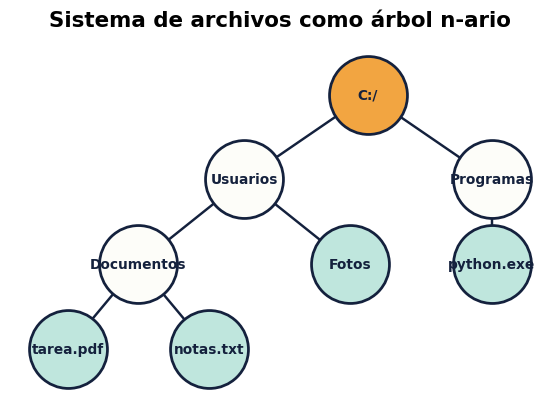

Peso: 8 · Altura: 3 · Grado: 2
Hojas: ['tarea.pdf', 'notas.txt', 'Fotos', 'python.exe']


In [ ]:
# Convierte un diccionario anidado (como un JSON) en un árbol y lo dibuja.

sistema_archivos = {
    "C:/": {
        "Usuarios": {
            "Documentos": {"tarea.pdf": None, "notas.txt": None},
            "Fotos": {},
        },
        "Programas": {"python.exe": None},
    }
}


def dict_a_arbol(nombre, contenido):
    """Crea un Nodo por clave; un valor None o {} vacío es una hoja."""
    nodo = Nodo(nombre)
    if isinstance(contenido, dict):
        for clave, valor in contenido.items():
            nodo.agregar(dict_a_arbol(clave, valor))
    elif contenido is not None:
        raise ValueError(f"Valor no soportado en '{nombre}': {contenido!r}")
    return nodo


try:
    (nombre_raiz, contenido_raiz), = sistema_archivos.items()
    arbol_archivos = dict_a_arbol(nombre_raiz, contenido_raiz)
except ValueError as error:
    print(f"⚠ Revisa el diccionario: {error}")
else:
    dibujar_arbol(arbol_archivos, hijos_general, etiqueta_valor,
                  titulo="Sistema de archivos como árbol n-ario",
                  marcar_hojas=True, tam_nodo=2600, tam_fuente=9,
                  espacio_x=2.0)
    plt.show()
    print(f"Peso: {peso(arbol_archivos)} · Altura: {altura(arbol_archivos)} · "
          f"Grado: {grado(arbol_archivos)}")
    print("Hojas:", hojas(arbol_archivos))

## 4. Árbol binario de búsqueda (BST)
Un **árbol binario** tiene como máximo **2 hijos** por nodo: izquierdo y derecho.

Un **BST** agrega una regla que se cumple **en cada nodo**:

$$\text{izquierda} \le \text{nodo} < \text{derecha}$$

En cada comparación se descarta la mitad del árbol, como al buscar en un diccionario de papel. Si el árbol está equilibrado, buscar cuesta **O(log n)**: con 1.000.000 de datos bastan unas 20 comparaciones.

La inserción y la búsqueda se escriben **de forma iterativa** para evitar el límite de recursión de Python con árboles muy altos.

In [ ]:
# Implementa un BST con inserción, búsqueda, recorridos, altura y peso.


class NodoBST:
    """Nodo de árbol binario: valor, hijo izquierdo e hijo derecho."""

    __slots__ = ("valor", "izq", "der")

    def __init__(self, valor):
        self.valor = valor
        self.izq = None
        self.der = None


class BST:
    """Árbol binario de búsqueda: izquierda <= nodo < derecha."""

    def __init__(self, valores=None):
        self.raiz = None
        for valor in valores or []:
            self.insertar(valor)

    def insertar(self, valor):
        """Inserta un valor recorriendo el árbol desde la raíz (iterativo)."""
        nuevo = NodoBST(valor)
        if self.raiz is None:
            self.raiz = nuevo
            return
        actual = self.raiz
        while True:
            if valor <= actual.valor:
                if actual.izq is None:
                    actual.izq = nuevo
                    return
                actual = actual.izq
            else:
                if actual.der is None:
                    actual.der = nuevo
                    return
                actual = actual.der

    def buscar(self, valor):
        """Devuelve (encontrado, camino) donde camino es la lista de nodos visitados."""
        camino = []
        actual = self.raiz
        while actual is not None:
            camino.append(actual)
            if valor == actual.valor:
                return True, camino
            actual = actual.izq if valor < actual.valor else actual.der
        return False, camino

    # --- Recorridos en profundidad (DFS) ---------------------------------
    def preorden(self):
        """Nodo -> izquierda -> derecha."""
        resultado = []

        def visitar(n):
            if n:
                resultado.append(n)
                visitar(n.izq)
                visitar(n.der)
        visitar(self.raiz)
        return resultado

    def inorden(self):
        """Izquierda -> nodo -> derecha (en un BST sale ordenado)."""
        resultado = []

        def visitar(n):
            if n:
                visitar(n.izq)
                resultado.append(n)
                visitar(n.der)
        visitar(self.raiz)
        return resultado

    def postorden(self):
        """Izquierda -> derecha -> nodo."""
        resultado = []

        def visitar(n):
            if n:
                visitar(n.izq)
                visitar(n.der)
                resultado.append(n)
        visitar(self.raiz)
        return resultado

    # --- Recorrido por niveles (BFS) -------------------------------------
    def por_niveles(self):
        """Nivel por nivel, de izquierda a derecha, usando una cola."""
        if self.raiz is None:
            return []
        resultado, cola = [], deque([self.raiz])
        while cola:
            nodo = cola.popleft()
            resultado.append(nodo)
            cola.extend(h for h in (nodo.izq, nodo.der) if h)
        return resultado

    # --- Medidas (iterativas para soportar árboles altos) ----------------
    def altura(self):
        """Altura en aristas calculada por niveles (-1 si está vacío)."""
        if self.raiz is None:
            return -1
        niveles, cola = -1, deque([self.raiz])
        while cola:
            niveles += 1
            for _ in range(len(cola)):
                nodo = cola.popleft()
                cola.extend(h for h in (nodo.izq, nodo.der) if h)
        return niveles

    def peso(self):
        """Número de nodos."""
        return len(self.por_niveles())


def hijos_binario(nodo):
    """[izq, der] conservando None para que se vea el lado correcto."""
    if nodo.izq is None and nodo.der is None:
        return []
    return [nodo.izq, nodo.der]


def valores(nodos):
    """Convierte una lista de nodos en la lista de sus valores."""
    return [n.valor for n in nodos]


print("Clase BST lista ✔")

Clase BST lista ✔


Buscar 5: encontrado en 3 comparaciones
Camino: 6 -> 3 -> 5


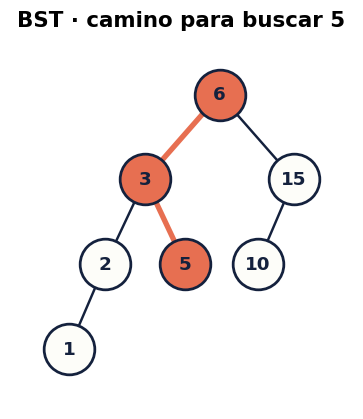

In [ ]:
# Construye el BST de trabajo y resalta el camino de búsqueda de un valor.

DATOS_BST = [6, 3, 15, 2, 5, 10, 1]
VALOR_A_BUSCAR = 5          # cámbialo para ver otros caminos

arbol = BST(DATOS_BST)
encontrado, camino = arbol.buscar(VALOR_A_BUSCAR)

estado = "encontrado" if encontrado else "NO encontrado"
print(f"Buscar {VALOR_A_BUSCAR}: {estado} en {len(camino)} comparaciones")
print("Camino:", " -> ".join(str(v) for v in valores(camino)))

dibujar_arbol(arbol.raiz, hijos_binario, etiqueta_valor,
              titulo=f"BST · camino para buscar {VALOR_A_BUSCAR}",
              resaltar=camino)
plt.show()

## 5. Recorridos de un árbol
Recorrer es **visitar cada nodo exactamente una vez**: cuesta **O(n)**.

| Recorrido | Orden | Uso real |
|---|---|---|
| **Pre-orden** | nodo → izq → der | Copiar o guardar (serializar) un árbol |
| **In-orden** | izq → nodo → der | Listar un BST **ordenado** |
| **Post-orden** | izq → der → nodo | Calcular el tamaño de una carpeta, borrar un árbol |
| **Por niveles (BFS)** | nivel a nivel con una **cola** | Contactos de 1.º, 2.º y 3.er grado en una red |

💡 **Truco:** el prefijo dice *cuándo* se visita el nodo: **pre** = antes, **in** = en medio, **post** = después.

En las figuras, el número oscuro junto a cada nodo indica el orden de visita.

Pre-orden (nodo, izq, der)     [6, 3, 2, 1, 5, 15, 10]
In-orden (izq, nodo, der)      [1, 2, 3, 5, 6, 10, 15]
Post-orden (izq, der, nodo)    [1, 2, 5, 3, 10, 15, 6]
Por niveles / BFS (cola)       [6, 3, 15, 2, 5, 10, 1]


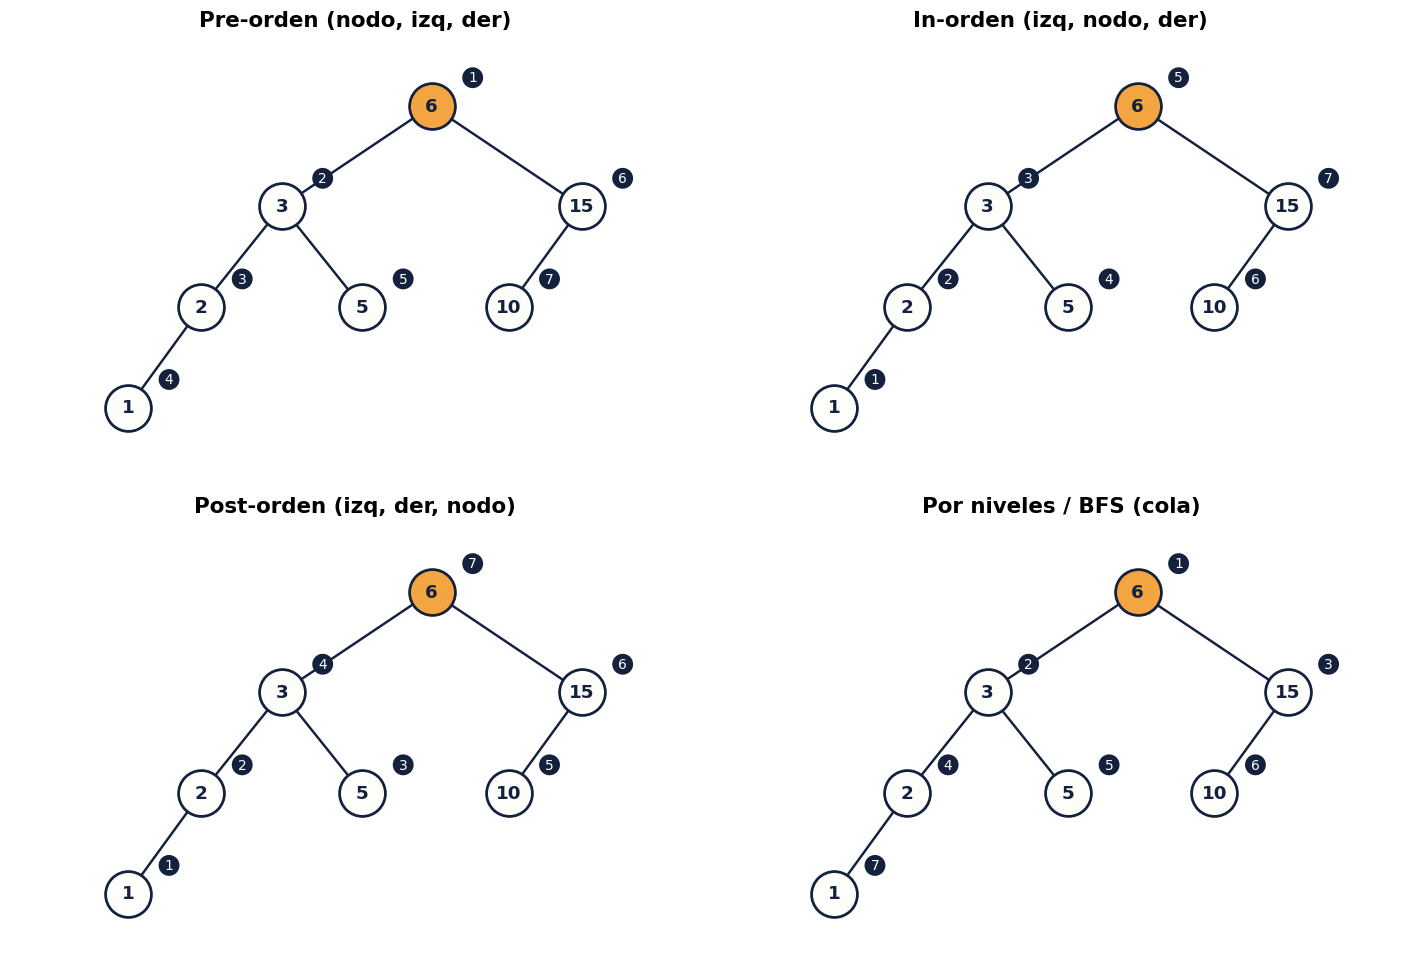

In [ ]:
# Calcula los cuatro recorridos y los dibuja con el orden de visita.

recorridos = {
    "Pre-orden (nodo, izq, der)": arbol.preorden(),
    "In-orden (izq, nodo, der)": arbol.inorden(),
    "Post-orden (izq, der, nodo)": arbol.postorden(),
    "Por niveles / BFS (cola)": arbol.por_niveles(),
}

for nombre, nodos in recorridos.items():
    print(f"{nombre:<30} {valores(nodos)}")

fig, ejes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (nombre, nodos) in zip(ejes.flat, recorridos.items()):
    dibujar_arbol(arbol.raiz, hijos_binario, etiqueta_valor, titulo=nombre,
                  orden_visita=nodos, ax=ax, tam_nodo=900)
plt.tight_layout()
plt.show()

## 6. Experimento: ¿por qué importa el orden de inserción?
Si los datos llegan **ordenados**, cada nuevo valor queda como hijo derecho del anterior y el BST **degenera en una lista**: la búsqueda pasa de **O(log n)** a **O(n)**.

Comparamos dos BST con 1.000 valores cada uno:
1. valores en **orden aleatorio**,
2. valores **ya ordenados** (peor caso).

Aleatorio  altura =   20 · 100 búsquedas en 0.16 ms
Ordenado   altura =  999 · 100 búsquedas en 5.55 ms

Referencia teórica: log2(1000) ≈ 10.0
Un BST aleatorio no queda perfecto (altura ≈ 2 a 3 veces log2 n),
pero sigue muy lejos de las n − 1 del caso ordenado.


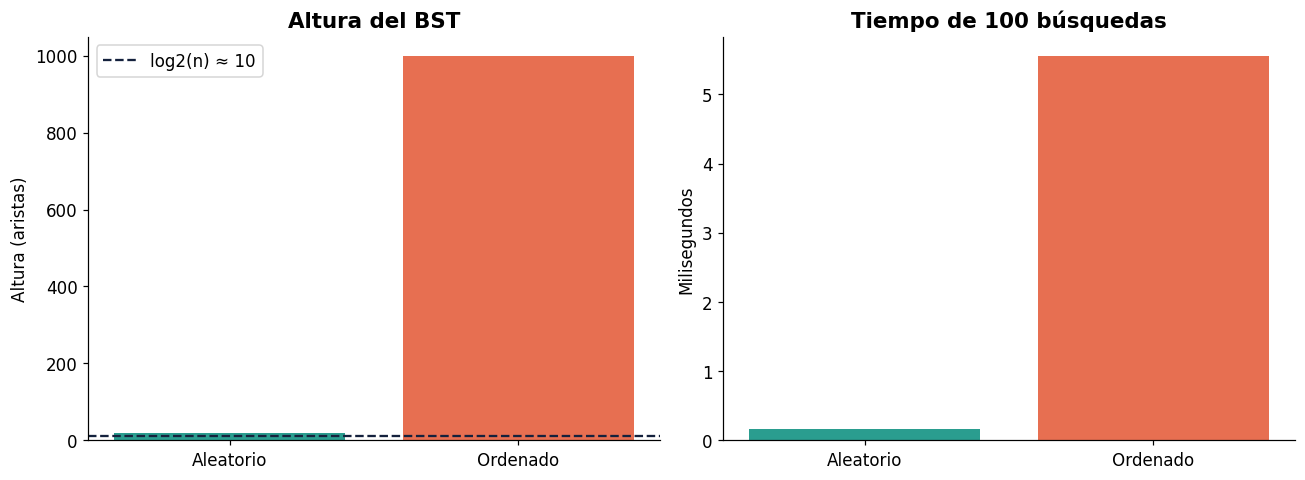

In [ ]:
# Compara altura y tiempo de búsqueda de un BST aleatorio contra uno ordenado.
import math

N = 1000
BUSQUEDAS = 100

datos_aleatorios = random.sample(range(N * 10), N)
datos_ordenados = sorted(datos_aleatorios)

resultados = {}
for nombre, datos in [("Aleatorio", datos_aleatorios), ("Ordenado", datos_ordenados)]:
    bst = BST(datos)
    objetivos = random.sample(datos, BUSQUEDAS)
    inicio = time.perf_counter()
    for objetivo in objetivos:
        bst.buscar(objetivo)
    milisegundos = (time.perf_counter() - inicio) * 1000
    resultados[nombre] = {"altura": bst.altura(), "ms": milisegundos}
    print(f"{nombre:<10} altura = {bst.altura():>4} · "
          f"{BUSQUEDAS} búsquedas en {milisegundos:.2f} ms")

print(f"\nReferencia teórica: log2({N}) ≈ {math.log2(N):.1f}")
print("Un BST aleatorio no queda perfecto (altura ≈ 2 a 3 veces log2 n),")
print("pero sigue muy lejos de las n − 1 del caso ordenado.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
nombres = list(resultados)
colores = ["#2A9D8F", COLOR_RESALTE]

ax1.bar(nombres, [r["altura"] for r in resultados.values()], color=colores)
ax1.axhline(math.log2(N), color=COLOR_BORDE, linestyle="--",
            label=f"log2(n) ≈ {math.log2(N):.0f}")
ax1.set_title("Altura del BST")
ax1.set_ylabel("Altura (aristas)")
ax1.legend()

ax2.bar(nombres, [r["ms"] for r in resultados.values()], color=colores)
ax2.set_title(f"Tiempo de {BUSQUEDAS} búsquedas")
ax2.set_ylabel("Milisegundos")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

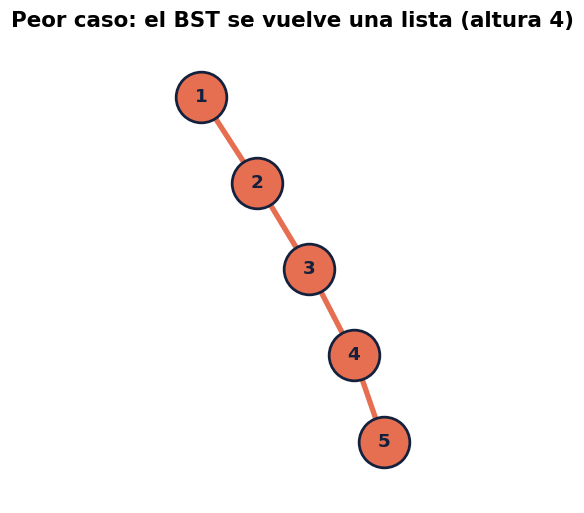

In [ ]:
# Dibuja en pequeño el peor caso: insertar 1, 2, 3, 4, 5 en orden.
degenerado = BST([1, 2, 3, 4, 5])
dibujar_arbol(degenerado.raiz, hijos_binario, etiqueta_valor,
              titulo=f"Peor caso: el BST se vuelve una lista (altura {degenerado.altura()})",
              resaltar=degenerado.por_niveles())
plt.show()

## 7. Árbol balanceado
Los árboles **AVL** y **Rojo-Negro** se **reorganizan solos** con *rotaciones* al insertar o borrar, y garantizan **O(log n)** siempre.

- **AVL:** las alturas de los dos subárboles de cada nodo difieren como máximo en 1.
- **Rojo-Negro:** colorea los nodos para mantener un equilibrio aproximado (lo usan `TreeMap` de Java y `std::map` de C++).

Aquí vemos el resultado de un árbol balanceado construyéndolo desde una lista ordenada: se toma siempre el **elemento del medio** como raíz.

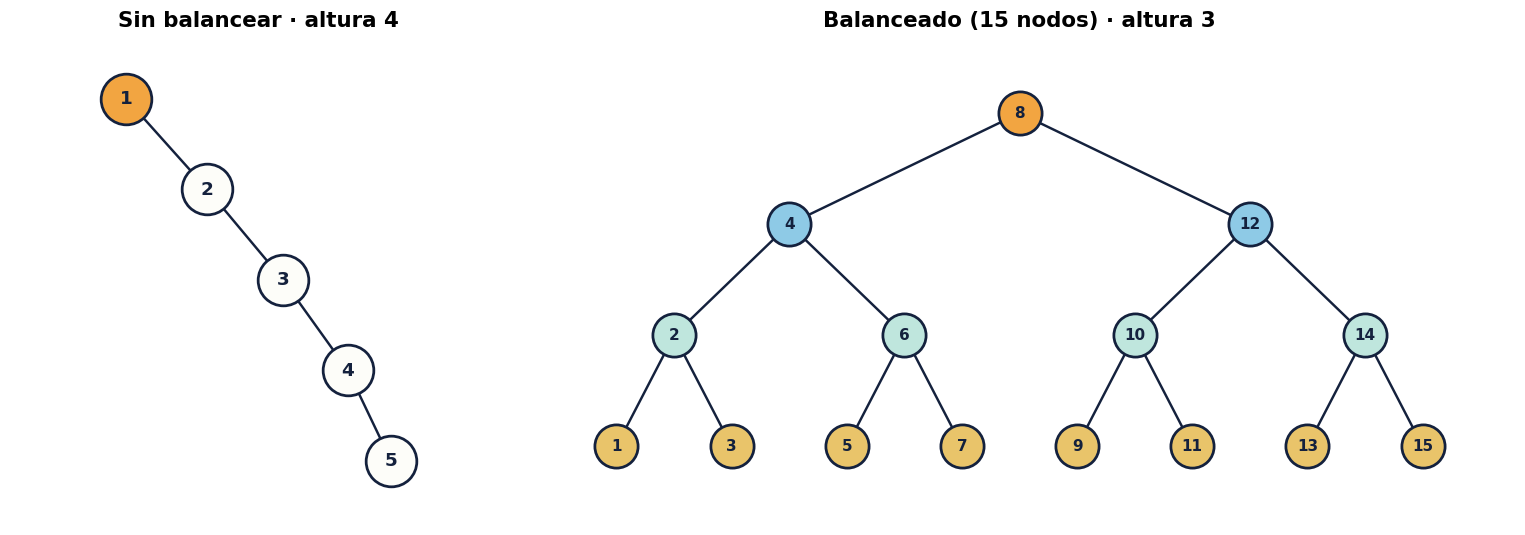

In [ ]:
# Construye un BST balanceado tomando el elemento central como raíz.


def construir_balanceado(ordenados):
    """Devuelve la raíz de un BST balanceado a partir de una lista ordenada."""
    if not ordenados:
        return None
    medio = len(ordenados) // 2
    nodo = NodoBST(ordenados[medio])
    nodo.izq = construir_balanceado(ordenados[:medio])
    nodo.der = construir_balanceado(ordenados[medio + 1:])
    return nodo

# Aseguramos que la variable 'degenerado' esté definida
degenerado = BST([1, 2, 3, 4, 5])

balanceado = BST()
balanceado.raiz = construir_balanceado(list(range(1, 16)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5),
                               gridspec_kw={"width_ratios": [1, 2]})
dibujar_arbol(degenerado.raiz, hijos_binario, etiqueta_valor,
              titulo=f"Sin balancear · altura {degenerado.altura()}", ax=ax1)
dibujar_arbol(balanceado.raiz, hijos_binario, etiqueta_valor,
              titulo=f"Balanceado (15 nodos) · altura {balanceado.altura()}",
              colorear_niveles=True, ax=ax2, tam_nodo=800, tam_fuente=10)
plt.tight_layout()
plt.show()

## 8. Heap (montículo)
Un **heap** es un **árbol binario completo** (todos los niveles llenos, el último de izquierda a derecha) en el que cada padre es **≤ sus hijos** (*min-heap*).

- Se guarda en un **arreglo**, sin punteros: los hijos del índice *i* están en **2i + 1** y **2i + 2**.
- Ver el mínimo cuesta **O(1)**; insertar o extraer, **O(log n)**.
- Es la base de las **colas de prioridad**: como el **triage de urgencias**, que atiende primero al paciente más grave.

Python lo trae en el módulo `heapq`.

Arreglo original : [9, 5, 8, 1, 7, 3]
Arreglo heap     : [1, 5, 3, 9, 7, 8]
  índice 0: valor 1 -> hijos [5, 3]
  índice 1: valor 5 -> hijos [9, 7]
  índice 2: valor 3 -> hijos [8]
  índice 3: valor 9 -> hijos []
  índice 4: valor 7 -> hijos []
  índice 5: valor 8 -> hijos []


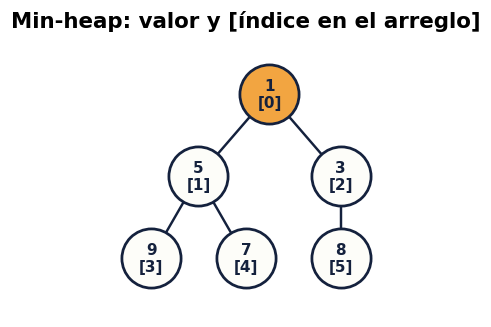

Orden de atención: [1, 3, 5, 7, 8, 9]


In [ ]:
# Crea un min-heap con heapq y lo dibuja como árbol a partir del arreglo.

prioridades = [9, 5, 8, 1, 7, 3]
heap = prioridades.copy()
heapq.heapify(heap)

print("Arreglo original :", prioridades)
print("Arreglo heap     :", heap)
for i, valor in enumerate(heap):
    hijos = [heap[j] for j in (2 * i + 1, 2 * i + 2) if j < len(heap)]
    print(f"  índice {i}: valor {valor} -> hijos {hijos}")


def arreglo_a_arbol(arreglo, i=0):
    """Convierte un arreglo de heap en nodos de árbol (hijos 2i+1 y 2i+2)."""
    if i >= len(arreglo):
        return None
    nodo = Nodo(f"{arreglo[i]}\n[{i}]")
    for j in (2 * i + 1, 2 * i + 2):
        hijo = arreglo_a_arbol(arreglo, j)
        if hijo is not None:
            nodo.agregar(hijo)
    return nodo


dibujar_arbol(arreglo_a_arbol(heap), hijos_general, etiqueta_valor,
              titulo="Min-heap: valor y [índice en el arreglo]",
              tam_nodo=1500, tam_fuente=10)
plt.show()

# Extraer en orden de prioridad (como atender pacientes por gravedad).
orden_atencion = [heapq.heappop(heap) for _ in range(len(heap))]
print("Orden de atención:", orden_atencion)

## 9. Trie (árbol de prefijos)
Un **trie** guarda una **letra por nodo**; las palabras que comparten prefijo comparten camino. Buscar una palabra cuesta lo que mide la palabra, **no** lo que mide el diccionario.

**Ejemplo real:** el **autocompletado** del teclado del celular o del buscador. En la figura, los nodos coloreados marcan el final de una palabra.

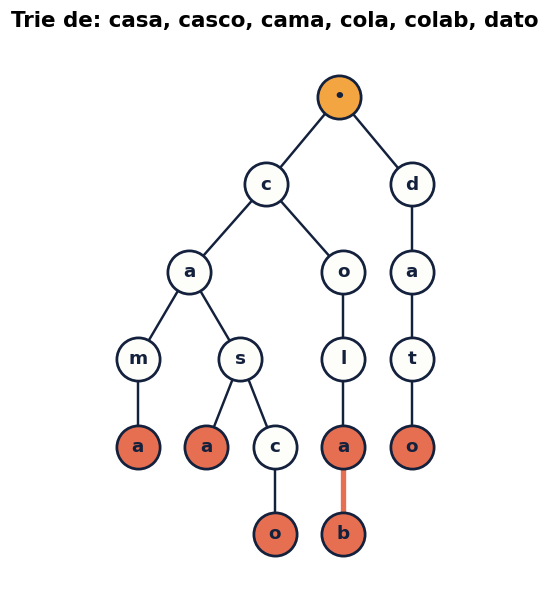

Autocompletar 'ca': ['cama', 'casa', 'casco']
Autocompletar 'col': ['cola', 'colab']
Autocompletar 'x': sin resultados


In [ ]:
# Construye un trie con varias palabras, lo dibuja y prueba el autocompletado.


class NodoTrie:
    """Nodo de trie: una letra, sus hijos por letra y si termina una palabra."""

    def __init__(self, letra=""):
        self.letra = letra
        self.hijos = {}
        self.fin = False


class Trie:
    """Árbol de prefijos para guardar y autocompletar palabras."""

    def __init__(self, palabras=None):
        self.raiz = NodoTrie("•")
        for palabra in palabras or []:
            self.insertar(palabra)

    def insertar(self, palabra):
        if not isinstance(palabra, str) or not palabra:
            raise ValueError("Solo se pueden insertar textos no vacíos.")
        nodo = self.raiz
        for letra in palabra.lower():
            nodo = nodo.hijos.setdefault(letra, NodoTrie(letra))
        nodo.fin = True

    def autocompletar(self, prefijo):
        """Devuelve todas las palabras que empiezan por el prefijo."""
        nodo = self.raiz
        for letra in prefijo.lower():
            if letra not in nodo.hijos:
                return []
            nodo = nodo.hijos[letra]
        palabras = []

        def recolectar(n, acumulado):
            if n.fin:
                palabras.append(acumulado)
            for letra, hijo in sorted(n.hijos.items()):
                recolectar(hijo, acumulado + letra)
        recolectar(nodo, prefijo.lower())
        return palabras


PALABRAS = ["casa", "casco", "cama", "cola", "colab", "dato"]
trie = Trie(PALABRAS)


def nodos_fin(nodo):
    """Lista de nodos donde termina una palabra."""
    encontrados = [nodo] if nodo.fin else []
    for hijo in nodo.hijos.values():
        encontrados.extend(nodos_fin(hijo))
    return encontrados


dibujar_arbol(trie.raiz,
              hijos_fn=lambda n: [n.hijos[k] for k in sorted(n.hijos)],
              etiqueta_fn=lambda n: n.letra,
              titulo="Trie de: " + ", ".join(PALABRAS),
              resaltar=nodos_fin(trie.raiz), tam_nodo=800)
plt.show()

for prefijo in ["ca", "col", "x"]:
    print(f"Autocompletar '{prefijo}': {trie.autocompletar(prefijo) or 'sin resultados'}")

## 10. Árbol de decisión en Machine Learning
En un **árbol de decisión**:
- cada **nodo interno** es una pregunta sobre una variable (¿el pétalo mide menos de 2,45 cm?),
- cada **rama** es una respuesta,
- cada **hoja** es una predicción.

Es un modelo de **caja blanca**: se puede leer y explicar, por eso lo prefieren sectores como la banca. **Random Forest** y **XGBoost** combinan cientos de estos árboles que votan.

Entrenamos uno con el dataset **Iris** de `scikit-learn`.

Exactitud en prueba: 97.8%
Altura del árbol: 3 · Hojas: 5

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.55
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- class: 2



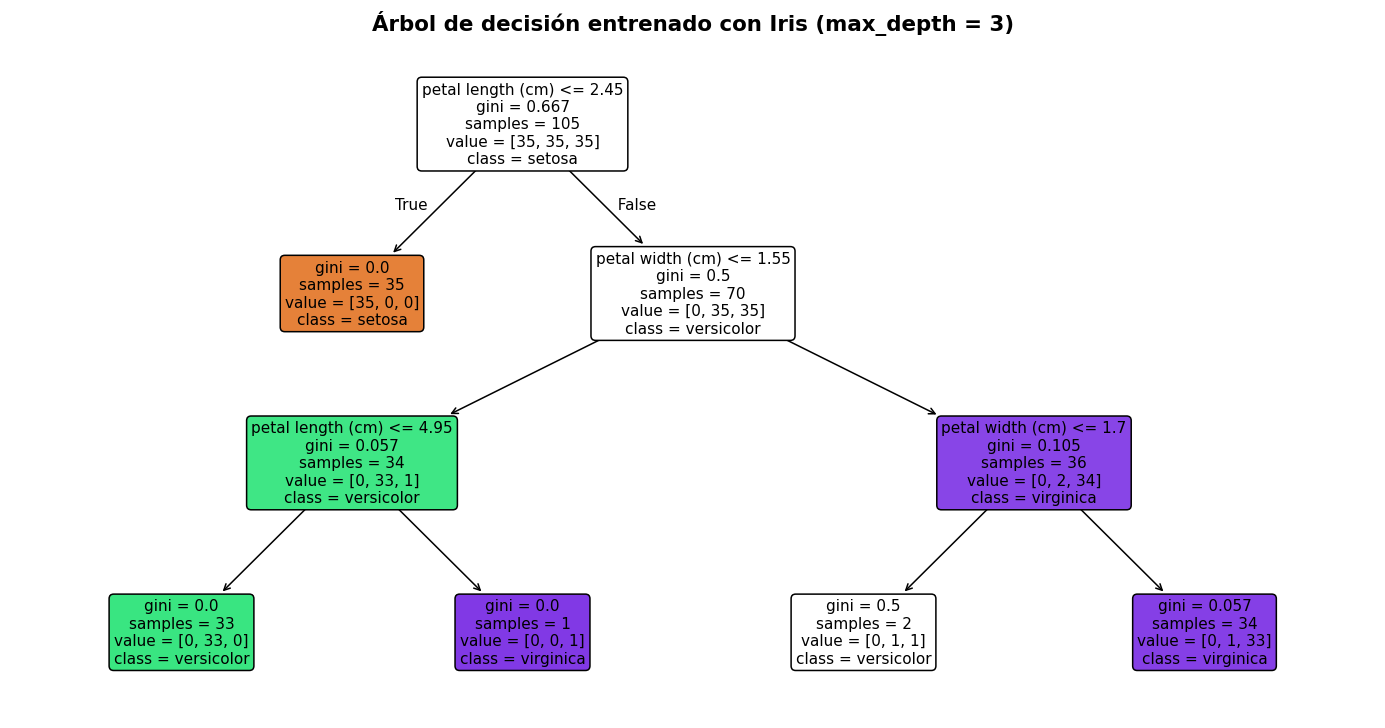

In [ ]:
# Entrena un árbol de decisión sobre Iris, lo evalúa y lo dibuja.
try:
    from sklearn.datasets import load_iris
    from sklearn.metrics import accuracy_score
    from sklearn.model_selection import train_test_split
    from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
except ImportError:
    print("⚠ scikit-learn no está disponible. Ejecuta: !pip install scikit-learn --quiet")
else:
    iris = load_iris()
    X_train, X_test, y_train, y_test = train_test_split(
        iris.data, iris.target, test_size=0.3, random_state=42, stratify=iris.target)

    modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
    modelo.fit(X_train, y_train)
    exactitud = accuracy_score(y_test, modelo.predict(X_test))

    print(f"Exactitud en prueba: {exactitud:.1%}")
    print(f"Altura del árbol: {modelo.get_depth()} · Hojas: {modelo.get_n_leaves()}\n")
    print(export_text(modelo, feature_names=list(iris.feature_names)))

    plt.figure(figsize=(16, 8))
    plot_tree(modelo, feature_names=iris.feature_names, class_names=iris.target_names,
              filled=True, rounded=True, fontsize=10)
    plt.title("Árbol de decisión entrenado con Iris (max_depth = 3)")
    plt.show()

## 📋 Resumen: ¿qué árbol uso?
| Tipo | Regla | Búsqueda | Cuándo usarlo |
|---|---|---|---|
| General / n-ario | 0 a N hijos | O(n) | Carpetas, DOM, JSON |
| Árbol B | n-ario balanceado | O(log n) | Índices de bases de datos |
| BST | izq ≤ nodo < der | O(log n) promedio, O(n) peor | Datos ordenados con pocos cambios |
| AVL / Rojo-Negro | BST autobalanceado | O(log n) garantizado | Datos ordenados que cambian mucho |
| Heap | Completo, padre ≤ hijos | Mínimo en O(1) | Colas de prioridad, triage |
| Trie | Una letra por nodo | O(largo de la palabra) | Autocompletado |
| Árbol de decisión | Una pregunta por nodo | O(altura) | Clasificación en ML |

## 11. 🛠️ Taller para practicar
1. Inserta en un BST, en este orden: **50, 30, 70, 20, 40, 60, 80, 35**. Dibuja el árbol y escribe sus recorridos.
2. Busca el **35** y el **65**: ¿cuántas comparaciones hace cada búsqueda?
3. Inserta **10, 20, 30, 40, 50** en un BST nuevo. ¿Qué altura tiene? ¿En qué orden habría que insertarlos para que quede equilibrado?
4. **Reto:** agrega a la clase `BST` un método `minimo()` y otro `maximo()`.
5. **Reto IA:** cambia `max_depth` del árbol de decisión a 1, 2 y 5. ¿Qué pasa con la exactitud?

Usa la celda siguiente como punto de partida.

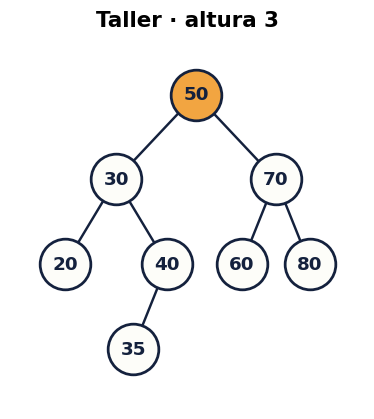

Pre-orden : [50, 30, 20, 40, 35, 70, 60, 80]
In-orden  : [20, 30, 35, 40, 50, 60, 70, 80]
Post-orden: [20, 35, 40, 30, 60, 80, 70, 50]
Niveles   : [50, 30, 70, 20, 40, 60, 80, 35]
Buscar 35: sí · 4 comparaciones
Buscar 65: no · 3 comparaciones


In [ ]:
# Taller: completa y ejecuta (punto de partida).
taller = BST([50, 30, 70, 20, 40, 60, 80, 35])

dibujar_arbol(taller.raiz, hijos_binario, etiqueta_valor,
              titulo=f"Taller · altura {taller.altura()}")
plt.show()

print("Pre-orden :", valores(taller.preorden()))
print("In-orden  :", valores(taller.inorden()))
print("Post-orden:", valores(taller.postorden()))
print("Niveles   :", valores(taller.por_niveles()))

for objetivo in (35, 65):
    hallado, ruta = taller.buscar(objetivo)
    print(f"Buscar {objetivo}: {'sí' if hallado else 'no'} · "
          f"{len(ruta)} comparaciones")

# TODO: punto 3 y retos 4 y 5.